# ProductLens 02 · Results analysis

Analysis of the trained system, run on CPU against the artifacts produced by notebook 01.

1. Training dynamics
2. Zero-shot vs fine-tuned retrieval on the held-out split
3. **Full-catalog retrieval:** held-out queries searched against all 121,549 products, across IVF probe settings
4. Browser encoder: INT8 ONNX vs PyTorch, accuracy and latency
5. Quantization study
6. Storage footprint
7. Comparison with alternative techniques

Inputs: `results/*.json` and `artifacts/` (model, index, metadata), plus `static_site/model/text.onnx` for
section 4. Figures are written to `docs/figures/` and measured numbers to `results/`.

In [1]:
import json, os, sys, time
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import load_model

ART, RES, FIG = ROOT / "artifacts", ROOT / "results", ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
THREADS = os.cpu_count() or 4
torch.set_num_threads(THREADS)

# Reference palette (validated categorical slots) and recessive chart chrome.
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, BASE = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "font.family": "DejaVu Sans",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "text.color": INK,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")

history = json.load(open(RES / "train_history.json"))
test = json.load(open(RES / "test_metrics.json"))
quant = json.load(open(RES / "quantization.json"))

C:\Users\ranje\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Training dynamics

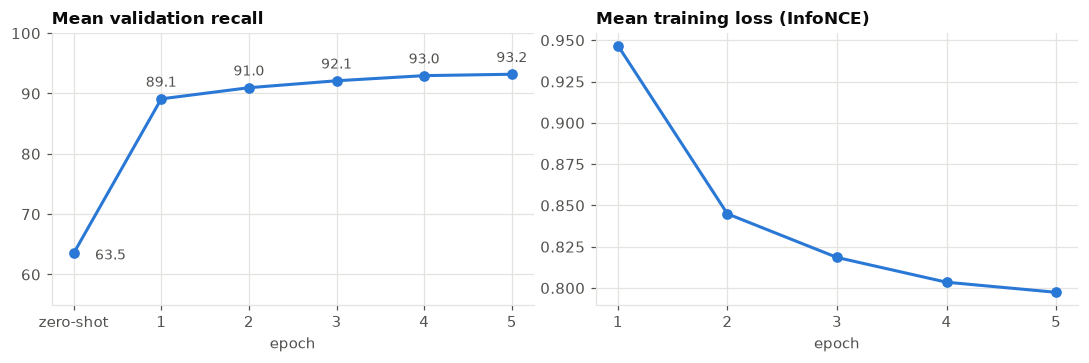

,epoch,text2image_R@1,image2text_R@1,mean_recall,train_loss,epoch_sec
0,1,75.89,75.84,89.11,0.9468,2318.8
1,2,79.68,79.53,90.96,0.8449,2318.3
2,3,82.23,81.98,92.11,0.8185,2316.6
3,4,84.02,83.63,92.96,0.8035,2309.1
4,5,84.38,84.29,93.19,0.7974,2309.9


In [2]:
epochs = list(range(len(history["epochs"]) + 1))
mean_recall = [history["zero_shot"]["mean_recall"]] + [e["mean_recall"] for e in history["epochs"]]
loss = [e["train_loss"] for e in history["epochs"]]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
a.plot(epochs, mean_recall, color=BLUE, lw=2, marker="o", ms=6)
for x, y in zip(epochs, mean_recall):
    a.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(14 if x == 0 else 0, -4 if x == 0 else 8),
               ha="left" if x == 0 else "center", color=INK2, fontsize=9)
a.set_xticks(epochs, ["zero-shot"] + [str(e) for e in epochs[1:]])
a.set_ylim(55, 100); a.set_xlabel("epoch"); a.set_title("Mean validation recall")
b.plot(epochs[1:], loss, color=BLUE, lw=2, marker="o", ms=6)
b.set_xticks(epochs[1:]); b.set_xlabel("epoch"); b.set_title("Mean training loss (InfoNCE)")
fig.tight_layout(); save(fig, "training_curves"); plt.show()
pd.DataFrame([{"epoch": e["epoch"] + 1, **{k: e[k] for k in
               ("text2image_R@1", "image2text_R@1", "mean_recall", "train_loss", "epoch_sec")}}
              for e in history["epochs"]])

Most of the gain arrives in the first epoch (63.5 to 89.1 mean recall). The remaining four epochs add a
further 4.1 points with diminishing returns, and validation recall never decreases, so there is no sign of
overfitting at this learning rate.

## 2. Zero-shot vs fine-tuned (held-out split, 6,077 products)

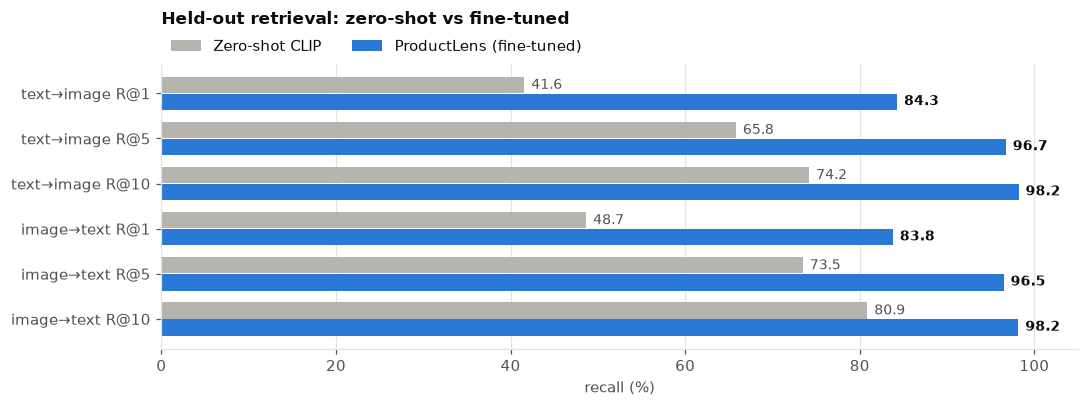

,metric,zero-shot,fine-tuned,gain (points)
0,text→image R@1,41.57,84.27,42.70
1,text→image R@5,65.81,96.73,30.92
2,text→image R@10,74.20,98.19,23.99
3,image→text R@1,48.66,83.79,35.13
4,image→text R@5,73.47,96.48,23.01
5,image→text R@10,80.86,98.16,17.30


In [3]:
keys = ["text2image_R@1", "text2image_R@5", "text2image_R@10", "image2text_R@1", "image2text_R@5", "image2text_R@10"]
labels = [k.replace("text2image_", "text→image ").replace("image2text_", "image→text ") for k in keys]
zs = [test["zero_shot"][k] for k in keys]
ft = [test["fine_tuned"][k] for k in keys]

fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(keys)); h = 0.36
ax.barh(y - h / 2 - 0.01, zs, h, color=BASE, label="Zero-shot CLIP")
ax.barh(y + h / 2 + 0.01, ft, h, color=BLUE, label="ProductLens (fine-tuned)")
for i in range(len(keys)):
    ax.text(zs[i] + 0.8, y[i] - h / 2, f"{zs[i]:.1f}", va="center", color=INK2, fontsize=9)
    ax.text(ft[i] + 0.8, y[i] + h / 2, f"{ft[i]:.1f}", va="center", color=INK, fontsize=9, weight="bold")
ax.set_yticks(y, labels); ax.invert_yaxis(); ax.set_xlim(0, 105); ax.set_xlabel("recall (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
ax.set_title("Held-out retrieval: zero-shot vs fine-tuned", pad=26)
fig.tight_layout(); save(fig, "zeroshot_vs_finetuned"); plt.show()
pd.DataFrame({"metric": labels, "zero-shot": zs, "fine-tuned": ft,
              "gain (points)": np.round(np.array(ft) - zs, 2)})

## 3. Full-catalog retrieval

The headline numbers above rank each test query against the 6,077 test products only. In production a query
competes with the **entire catalog**, including near-duplicate listings. Here every held-out product's text is
used as a query against the IVF-PQ index of all 121,549 products, and the probe count (`nprobe`, the number of
inverted lists scanned) is swept from 1 to all 1,024.

The catalog is stored in the same shuffled order as the split, so the test products are rows 6,077 to 12,153.

In [4]:
model, _, _, tok = load_model("ViT-B-32", "none", str(ART / "model.pt"))
model.eval()
meta = pd.read_parquet(ART / "meta.parquet")
N = len(meta); n_val = int(N * 0.05)
test_rows = np.arange(n_val, 2 * n_val)
texts = meta.text.iloc[test_rows].tolist()

t0 = time.time()
with torch.no_grad():
    q = torch.cat([F.normalize(model.encode_text(tok(texts[s:s + 256])).float(), dim=-1)
                   for s in range(0, len(texts), 256)]).numpy().astype("float32")
print(f"encoded {len(q):,} queries in {time.time() - t0:.1f}s")

index = faiss.read_index(str(ART / "index.faiss"))
ivf = faiss.extract_index_ivf(index)

def recall(I, rows):
    hit = I == rows[:, None]
    return {f"R@{k}": round(100 * float(hit[:, :k].any(1).mean()), 2) for k in (1, 5, 10)}

sweep = []
for nprobe in (1, 2, 4, 8, 16, 32, 64, 128, 256, 1024):
    ivf.nprobe = nprobe
    faiss.omp_set_num_threads(1)
    t = time.perf_counter()
    for i in range(300):
        index.search(q[i:i + 1], 10)
    ms = (time.perf_counter() - t) / 300 * 1000
    faiss.omp_set_num_threads(THREADS)
    _, I = index.search(q, 10)
    sweep.append({"nprobe": nprobe, **recall(I, test_rows), "ms_per_query_1thread": round(ms, 3)})
sweep = pd.DataFrame(sweep)
sweep

encoded 6,077 queries in 139.8s


,nprobe,R@1,R@5,R@10,ms_per_query_1thread
0,1,23.66,46.04,55.47,0.343
1,2,27.15,54.24,66.20,0.315
2,4,28.04,57.53,70.91,0.296
3,8,28.19,58.25,72.06,0.289
4,16,28.19,58.35,72.21,0.296
5,32,28.19,58.35,72.26,0.379
6,64,28.19,58.35,72.26,0.507
7,128,28.19,58.35,72.26,0.828
8,256,28.19,58.35,72.26,1.436
9,1024,28.19,58.35,72.26,5.093


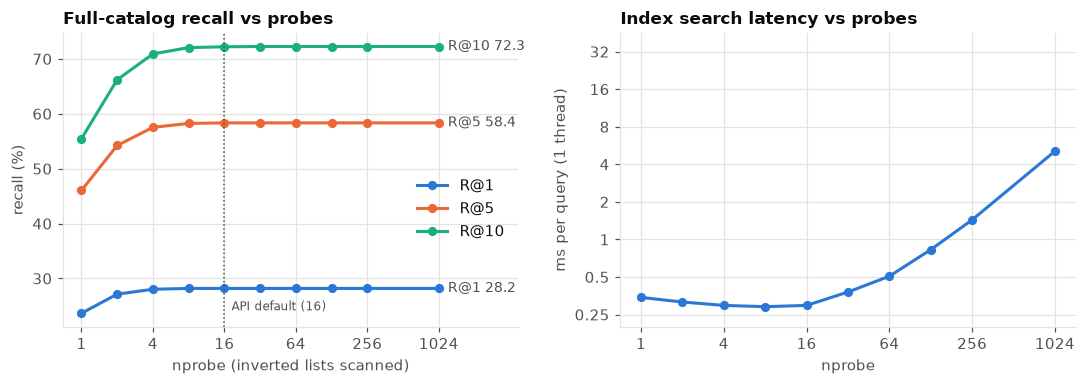

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
for k, c in (("R@1", BLUE), ("R@5", ORANGE), ("R@10", AQUA)):
    a.plot(sweep.nprobe, sweep[k], color=c, lw=2, marker="o", ms=5, label=k)
    a.annotate(f"{k} {sweep[k].iloc[-1]:.1f}", (sweep.nprobe.iloc[-1], sweep[k].iloc[-1]), xytext=(6, 0),
               textcoords="offset points", va="center", color=INK2, fontsize=9)
a.axvline(16, color=INK2, lw=1, ls=":")
a.text(17, sweep["R@1"].min(), " API default (16)", color=INK2, fontsize=8, va="bottom")
ticks = [1, 4, 16, 64, 256, 1024]
a.set_xscale("log", base=2); a.set_xticks(ticks, [str(t) for t in ticks]); a.minorticks_off()
a.set_xlabel("nprobe (inverted lists scanned)"); a.set_ylabel("recall (%)")
a.set_title("Full-catalog recall vs probes"); a.legend(loc="center right", bbox_to_anchor=(1.0, 0.4))
a.set_xlim(0.7, 4800)
b.plot(sweep.nprobe, sweep.ms_per_query_1thread, color=BLUE, lw=2, marker="o", ms=5)
b.set_xscale("log", base=2); b.set_xticks(ticks, [str(t) for t in ticks])
b.set_yscale("log"); b.minorticks_off()
yt = [0.25, 0.5, 1, 2, 4, 8, 16, 32]
b.set_yticks(yt, [f"{v:g}" for v in yt]); b.set_ylim(0.2, 45)
b.set_xlabel("nprobe"); b.set_ylabel("ms per query (1 thread)"); b.set_title("Index search latency vs probes")
fig.tight_layout(); save(fig, "full_catalog_nprobe"); plt.show()

json.dump({"catalog_size": N, "queries": len(q), "sweep": sweep.to_dict("records")},
          open(RES / "full_catalog_eval.json", "w"), indent=2)

Recall saturates by about 8 to 16 probes: past that point the extra lists never contain the correct
product, while search cost keeps growing roughly linearly with the number of probes. Full-catalog recall is
far lower than the held-out split figure. The next cell examines why.

### 3.1 Error analysis: what does the model retrieve instead?

For every held-out query whose top result is wrong, the wrong product's text is compared with the correct
product's text.

In [6]:
import difflib
ivf.nprobe = 1024
_, I = index.search(q, 10)
fail = I[:, 0] != test_rows
sims, same_name = [], []
for r, top in zip(test_rows[fail], I[fail, 0]):
    a, b = meta.text[r], meta.text[top]
    sims.append(difflib.SequenceMatcher(None, a[:150], b[:150]).ratio())
    same_name.append(a.split(". ")[0] == b.split(". ")[0])
sims = np.array(sims)
errors = {"queries": len(test_rows), "failures": int(fail.sum()),
          "failures_with_correct_in_top10": round(float((I[fail] == test_rows[fail][:, None]).any(1).mean()), 4),
          "failures_near_duplicate_text_gt_0.6": round(float((sims > 0.6).mean()), 4),
          "failures_text_similarity_median": round(float(np.median(sims)), 4),
          "failures_identical_name": round(float(np.mean(same_name)), 4)}
json.dump(errors, open(RES / "full_catalog_error_analysis.json", "w"), indent=2)
print(json.dumps(errors, indent=1))
pd.DataFrame([{"query (correct product)": meta.text[r][:90], "retrieved top-1": meta.text[t][:90]}
              for r, t in list(zip(test_rows[fail], I[fail, 0]))[:8]])

{
 "queries": 6077,
 "failures": 4364,
 "failures_with_correct_in_top10": 0.6137,
 "failures_near_duplicate_text_gt_0.6": 0.736,
 "failures_text_similarity_median": 0.8385,
 "failures_identical_name": 0.0442
}


,query (correct product),retrieved top-1
0,Amazon Brand - Solimo Designer Daddy's Girl an...,Amazon Brand - Solimo Designer Daddy's Girl an...
1,Amazon Brand – Rivet Table Lamp with Textured ...,Amazon Brand – Stone & Beam Industrial Round C...
2,Amazon Brand - Solimo Designer Blossom Weather...,Amazon Brand - Solimo Designer Blossom Weather...
3,Amazon Brand - Solimo Designer Multicolor Lady...,Amazon Brand - Solimo Designer Multicolor Lady...
4,Amazon Brand - Solimo Designer Button Jeans Al...,Amazon Brand - Solimo Designer Button Jeans Al...
5,AmazonCommercial 1/6 Size Stainless Steel Soli...,AmazonCommercial 1/4 Size Stainless Steel Soli...
6,Amazon Brand - Solimo Designer Donuts Blue Pat...,Amazon Brand - Solimo Designer Donuts 3D Print...
7,Amazon Brand – Rivet Mid-Century Ceramic Plant...,Amazon Brand – Rivet Mid-Century Ceramic Plant...


Most errors are **near-duplicate listings**, not unrelated products. The ABO catalog contains large
families of variants, for example one printed phone-case design sold for dozens of phone models, or the same
pan cover in 1/4 and 1/6 sizes. These variants share an identical or near-identical product photo, so an
image index cannot separate them; the model retrieves a sibling variant, and the correct item is usually
still in the top 10. Full-catalog Recall@1 therefore understates practical quality, and variant-aware
evaluation (counting any member of the product family as correct) or re-ranking on listing text would be
the appropriate next steps.

## 4. Browser encoder: INT8 ONNX vs PyTorch

The browser runs the INT8 ONNX text encoder. Here the same held-out queries are encoded with it, searched with
the same index, and compared with the fp32 PyTorch encoder, both for end-to-end recall and for single-query
encoding latency on this CPU.

In [7]:
import onnxruntime as ort
onnx_path = ROOT / "static_site" / "model" / "text.onnx"
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
ids = tok(texts).numpy()
t0 = time.time()
q8 = np.concatenate([sess.run(None, {"input_ids": ids[i:i + 1]})[0] for i in range(len(ids))]).astype("float32")
print(f"INT8 encode: {time.time() - t0:.1f}s for {len(ids):,} queries")
cos = (q * q8).sum(1)

def latency(fn, n=100):
    fn(0)
    t = time.perf_counter()
    for i in range(n):
        fn(i)
    return (time.perf_counter() - t) / n * 1000

torch.set_num_threads(1)
so = ort.SessionOptions(); so.intra_op_num_threads = 1
sess1 = ort.InferenceSession(str(onnx_path), so, providers=["CPUExecutionProvider"])
with torch.no_grad():
    ms_torch = latency(lambda i: model.encode_text(torch.from_numpy(ids[i:i + 1])))
ms_int8 = latency(lambda i: sess1.run(None, {"input_ids": ids[i:i + 1]}))
torch.set_num_threads(THREADS)

ivf.nprobe = 1024
_, I32 = index.search(q, 10)
_, I8 = index.search(q8, 10)
enc = pd.DataFrame([
    {"encoder": "PyTorch fp32", "size_mb": quant["selected"]["text"]["fp32_mb"],
     "ms_per_query_1thread": round(ms_torch, 1), **recall(I32, test_rows)},
    {"encoder": "ONNX INT8 (browser)", "size_mb": round(onnx_path.stat().st_size / 2**20, 1),
     "ms_per_query_1thread": round(ms_int8, 1), **recall(I8, test_rows)},
])
print(f"cosine(fp32, int8) over {len(cos):,} queries: min {cos.min():.4f}, mean {cos.mean():.4f}")
json.dump({"cosine_min": float(cos.min()), "cosine_mean": float(cos.mean()), "rows": enc.to_dict("records")},
          open(RES / "encoder_comparison.json", "w"), indent=2)
enc

INT8 encode: 86.7s for 6,077 queries


cosine(fp32, int8) over 6,077 queries: min 0.9824, mean 0.9974


,encoder,size_mb,ms_per_query_1thread,R@1,R@5,R@10
0,PyTorch fp32,242.4,125.5,28.19,58.35,72.26
1,ONNX INT8 (browser),69.9,44.6,27.51,57.99,71.98


## 5. Quantization study

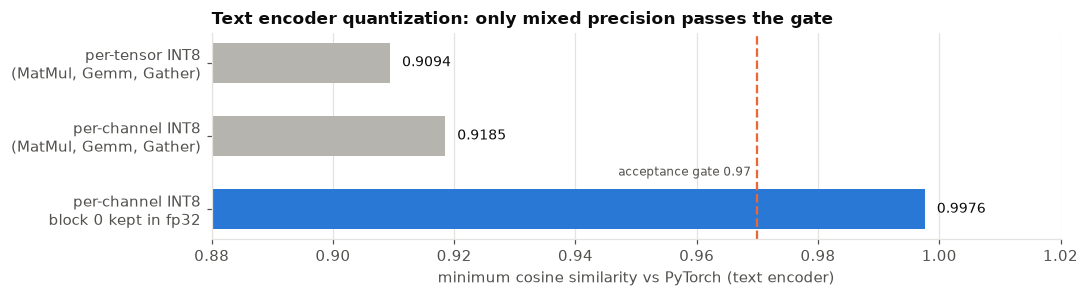

,fp32_blocks,min_cosine,int8_mb
0,[0],0.9976,70
1,[1],0.8950,70
2,"[0, 1]",0.9978,78
3,"[0, 1, 2]",0.9984,86


In [8]:
text_trials = [t for t in quant["trials"] if t["encoder"] == "text"]
names = ["per-tensor INT8\n(MatMul, Gemm, Gather)", "per-channel INT8\n(MatMul, Gemm, Gather)",
         "per-channel INT8\nblock 0 kept in fp32"]
vals = [t["min_cosine"] for t in text_trials]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.barh(range(len(vals)), vals, 0.55, color=[BASE, BASE, BLUE])
for i, v in enumerate(vals):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", color=INK, fontsize=9)
ax.axvline(quant["threshold"], color=ORANGE, lw=1.5, ls="--")
ax.text(quant["threshold"] - 0.001, 1.5, "acceptance gate 0.97", color=INK2, fontsize=8, ha="right", va="center")
ax.set_yticks(range(len(vals)), names); ax.invert_yaxis(); ax.set_xlim(0.88, 1.02)
ax.set_xlabel("minimum cosine similarity vs PyTorch (text encoder)"); ax.grid(axis="y", visible=False)
ax.set_title("Text encoder quantization: only mixed precision passes the gate")
fig.tight_layout(); save(fig, "quantization"); plt.show()
pd.DataFrame(quant["block_study_text"])

Dynamic INT8 with per-tensor or per-channel weight scales loses too much accuracy on the fine-tuned text
encoder (minimum cosine about 0.91). Quantizing only the second half of the network keeps cosine at 0.999,
which localises the problem to the early layers; a block-by-block study shows that **block 0 alone** is
responsible. Keeping that single block in fp32 restores cosine to 0.998 for about 9 MB, while keeping block 1
instead does not help (0.895). The image encoder quantizes cleanly (0.9955).

## 6. Storage footprint

In [9]:
site = ROOT / "static_site"
def mb(p):
    return round(sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 2**20, 1)
storage = pd.DataFrame([
    {"component": "Catalog vectors, float32 (exact)", "mb": round(N * 512 * 4 / 2**20, 1)},
    {"component": "Catalog vectors, float16", "mb": round(N * 512 * 2 / 2**20, 1)},
    {"component": "FAISS IVF-PQ index (API)", "mb": round((ART / "index.faiss").stat().st_size / 2**20, 1)},
    {"component": "Browser index arrays", "mb": mb(site / "index")},
    {"component": "Browser product metadata shards", "mb": mb(site / "meta")},
    {"component": "Text encoder, fp32 ONNX", "mb": quant["selected"]["text"]["fp32_mb"]},
    {"component": "Text encoder, INT8 ONNX (browser)", "mb": quant["selected"]["text"]["int8_mb"]},
    {"component": "Image encoder, fp32 ONNX", "mb": quant["selected"]["vision"]["fp32_mb"]},
    {"component": "Image encoder, INT8 ONNX (browser, lazy)", "mb": quant["selected"]["vision"]["int8_mb"]},
])
json.dump(storage.to_dict("records"), open(RES / "storage.json", "w"), indent=2)
storage

,component,mb
0,"Catalog vectors, float32 (exact)",237.4
1,"Catalog vectors, float16",118.7
2,FAISS IVF-PQ index (API),7.1
3,Browser index arrays,6.4
4,Browser product metadata shards,18.3
5,"Text encoder, fp32 ONNX",242.4
6,"Text encoder, INT8 ONNX (browser)",69.9
7,"Image encoder, fp32 ONNX",335.3
8,"Image encoder, INT8 ONNX (browser, lazy)",91.3


## 7. Comparison with alternative techniques

**Measured in this project**

| Approach | Text→image R@1, held-out split | Notes |
|---|---:|---|
| Zero-shot OpenCLIP ViT-B/32 | 41.6% | no training; generic image-caption alignment |
| ProductLens, fine-tuned fp32 | 84.3% | 5 epochs on a T4, about 3.3 hours |
| ProductLens, browser INT8 encoder | see section 4 | same index, INT8 query encoder |

**Alternatives considered (not run here; qualitative trade-offs)**

| Technique | Strength | Cost / limitation | Fit for ProductLens |
|---|---|---|---|
| Keyword search (BM25) over titles | exact brand and model-number matches, no GPU | no photo queries; fails on paraphrase ("couch" vs "sofa") | complementary; a hybrid re-ranker is a natural extension |
| Larger CLIP backbones (ViT-B/16, ViT-L/14) | typically stronger recall | 2 to 4 times slower encoders and larger downloads | better suited to a server-only deployment |
| SigLIP-style sigmoid loss | does not rely on very large batches | different pretrained checkpoint and recipe | promising for small-batch fine-tuning on a T4 |
| VLM re-rankers (for example BLIP-2) | fine-grained re-ranking of the top results | far too heavy for the browser; added latency | optional second stage behind the API |
| Exact flat index | exact search | 237 MB of float32 vectors; cost grows with the catalog | fine for the API at this size, too large for a browser |
| HNSW graph index | very low latency at high recall | stores full vectors plus graph links | good for the API; IVF-PQ wins on size |
| IVF-PQ (used) | 7 MB for 121K products; tunable recall and latency | approximate; small recall loss from PQ | chosen: fits both deployment targets |
